# RTENSO2026 2015/16 El Nino: Nino-index forecast plumes

Case-study companion to ESP-Lab `3a_sst_skill_ts.ipynb`. Instead of skill over many
start years, this notebook follows one event: Nino-index anomalies from the 2015
Feb/May/Aug/Nov starts of RTENSO2026 (`clim` and `obs` land/sea-ice/river ICs) and the
Reanalysis (BruteForce) 2015 hindcasts, against HadISST2.

Model anomalies remove the Reanalysis 1981-2010 lead-time climatology (drift
correction). Feb and Aug starts have no Reanalysis climatology; by default
(`CLIM_METHOD = "lead_drift"`) their climatology is the observed 1981-2010 target-month
climatology plus the Reanalysis drift at the same lead, averaged over the May and Nov
starts. The alternative `"target_month"` borrows the May/Nov climatology for the same
target month at the nearest lead, which is biased at short leads because the cold
tongue drifts about 1 C in the first months (see `rtenso_case.matched_climatology`). Observed
anomalies are relative to the HadISST2 1981-2010 monthly climatology. Indices use
`TS` box means (all-ocean boxes), as in 3a.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from datetime import datetime

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

from matplotlib.colors import BoundaryNorm
from cartopy.util import add_cyclic_point
from esp_lab.utils import colormap_utils as mycolors
from esp_lab.utils.netcdf_utils import atomic_to_netcdf

import rtenso_case as rc

def to_datetime(times):
    return [datetime(t.year, t.month, 15) for t in np.atleast_1d(times)]

### Run controls

In [2]:
# "auto": reuse valid caches, rebuild stale ones; "rebuild": recompute; "require": fail if a cache is missing
derivation_mode = "auto"
# Feb/Aug drift correction: "lead_drift" (obs target-month climatology + Reanalysis drift at the same lead) or "target_month"
CLIM_METHOD = "lead_drift"

INDICES = ["Nino3.4", "ONI", "Nino3", "Nino4", "Nino12"]   # ONI: 3-month running mean of Nino3.4
INIT_MONTHS = [2, 5, 8, 11]
MONTH_NAMES = {2: "Feb", 5: "May", 8: "Aug", 11: "Nov"}

# Hindcast year and cases. Each case reads
# <post_root>/<case_prefix>_<CASE_YEAR><MM>0100/ENxx/post/... (rc.post_root: RTENSO2026/post_process
# for RTENSO2026 cases, raw_model_root otherwise); "source" names
# the cached index files, "init_months" the starts the case has.
CASE_YEAR = 2015
MODEL_PREFIX = "WCYCL20TR_ne30pg2_r05_IcoswISC30E3r5"
CASES = {
    "Reanalysis-CLIM": {
        "case_prefix": f"{MODEL_PREFIX}_RTENSO2026_clim",
        "source": "RTENSO2026_clim",
        "init_months": (2, 5, 8, 11),
        "color": "tab:blue",
    },
    "Reanalysis-OBS": {
        "case_prefix": f"{MODEL_PREFIX}_RTENSO2026_obs",
        "source": "RTENSO2026_obs",
        "init_months": (2, 5, 8, 11),
        "color": "tab:orange",
    },
    # Placeholder: obs ICs with NSIDCv6 sea ice; set init_months once the runs are post-processed.
    "Reanalysis-NSIDC": {
        "case_prefix": f"{MODEL_PREFIX}_RTENSO2026_obs_ice_nsidc",
        "source": "RTENSO2026_obs_ice_nsidc",
        "init_months": (),
        "color": "tab:red",
    },
    "Reanalysis-FOSIRL": {
        "case_prefix": f"{MODEL_PREFIX}_BruteForce",
        "source": "Reanalysis",
        "init_months": (2, 5, 8, 11),
        "color": "tab:green",
    },
}
CASES = {name: case for name, case in CASES.items() if case["init_months"]}   # drop placeholders
PEAK_SEASON = {"label": "DJF 2015/16", "months": [(2015, 12), (2016, 1), (2016, 2)]}

OUTDIR = rc.diag_dir("RTENSO2026", "case_study", "sst_index")
OUTDIR.mkdir(parents=True, exist_ok=True)
print("figures ->", rc.figure_dir())

figures -> /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_rtenso2026_case


### Observed and forecast Nino indices

In [3]:
%%time
obs_ts = rc.obs_anomaly("TS", mode=derivation_mode)
obs_index = rc.nino_indices(obs_ts, INDICES)

fc_index = {}  # (case, init) -> Dataset of (member, lead) index anomalies
for case in CASES:
    for init in INIT_MONTHS:
        if init not in CASES[case]["init_months"]:
            continue
        anom = rc.hindcast_anomaly(CASES[case]["case_prefix"], init, "TS", year=CASE_YEAR,
                                   method=CLIM_METHOD, mode=derivation_mode)
        if anom is None:
            print(f"[{case} init{init:02d}] not available")
            continue
        ds = rc.nino_indices(anom, INDICES)
        ds.attrs.update(case=case, init_month=init, climatology_method=anom.attrs["climatology_method"])
        fc_index[(case, init)] = ds.load()
        source = CASES[case]["source"]
        atomic_to_netcdf(ds.drop_vars("time"), OUTDIR / f"{source}_init{init:02d}_TS_y{CASE_YEAR}_N{ds.sizes['member']}_M{ds.sizes['lead']}_NinoSST_mon.nc")
        print(f"[{case} init{init:02d}] {ds.sizes['member']} members, Nino3.4 lead 0 = {float(ds['Nino3.4'].isel(lead=0).mean()):.2f} C")

[Reanalysis-CLIM init02] 10 members, Nino3.4 lead 0 = 0.83 C
[Reanalysis-CLIM init05] 10 members, Nino3.4 lead 0 = 1.27 C
[Reanalysis-CLIM init08] 10 members, Nino3.4 lead 0 = 1.85 C
[Reanalysis-CLIM init11] 10 members, Nino3.4 lead 0 = 2.76 C
[Reanalysis-OBS init02] 10 members, Nino3.4 lead 0 = 0.84 C
[Reanalysis-OBS init05] 10 members, Nino3.4 lead 0 = 1.30 C
[Reanalysis-OBS init08] 10 members, Nino3.4 lead 0 = 1.85 C
[Reanalysis-OBS init11] 10 members, Nino3.4 lead 0 = 2.76 C
[Reanalysis-FOSIRL init02] 10 members, Nino3.4 lead 0 = 0.82 C
[Reanalysis-FOSIRL init05] 10 members, Nino3.4 lead 0 = 1.27 C
[Reanalysis-FOSIRL init08] 10 members, Nino3.4 lead 0 = 1.83 C
[Reanalysis-FOSIRL init11] 10 members, Nino3.4 lead 0 = 2.74 C
CPU times: user 3.7 s, sys: 4.35 s, total: 8.04 s
Wall time: 16.2 s


### Forecast plumes

Thin lines are members, thick lines ensemble means, black is HadISST2. The dashed vertical line marks each start.

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_rtenso2026_case/fig_rtenso2026_enso_plume_nino3_4.png


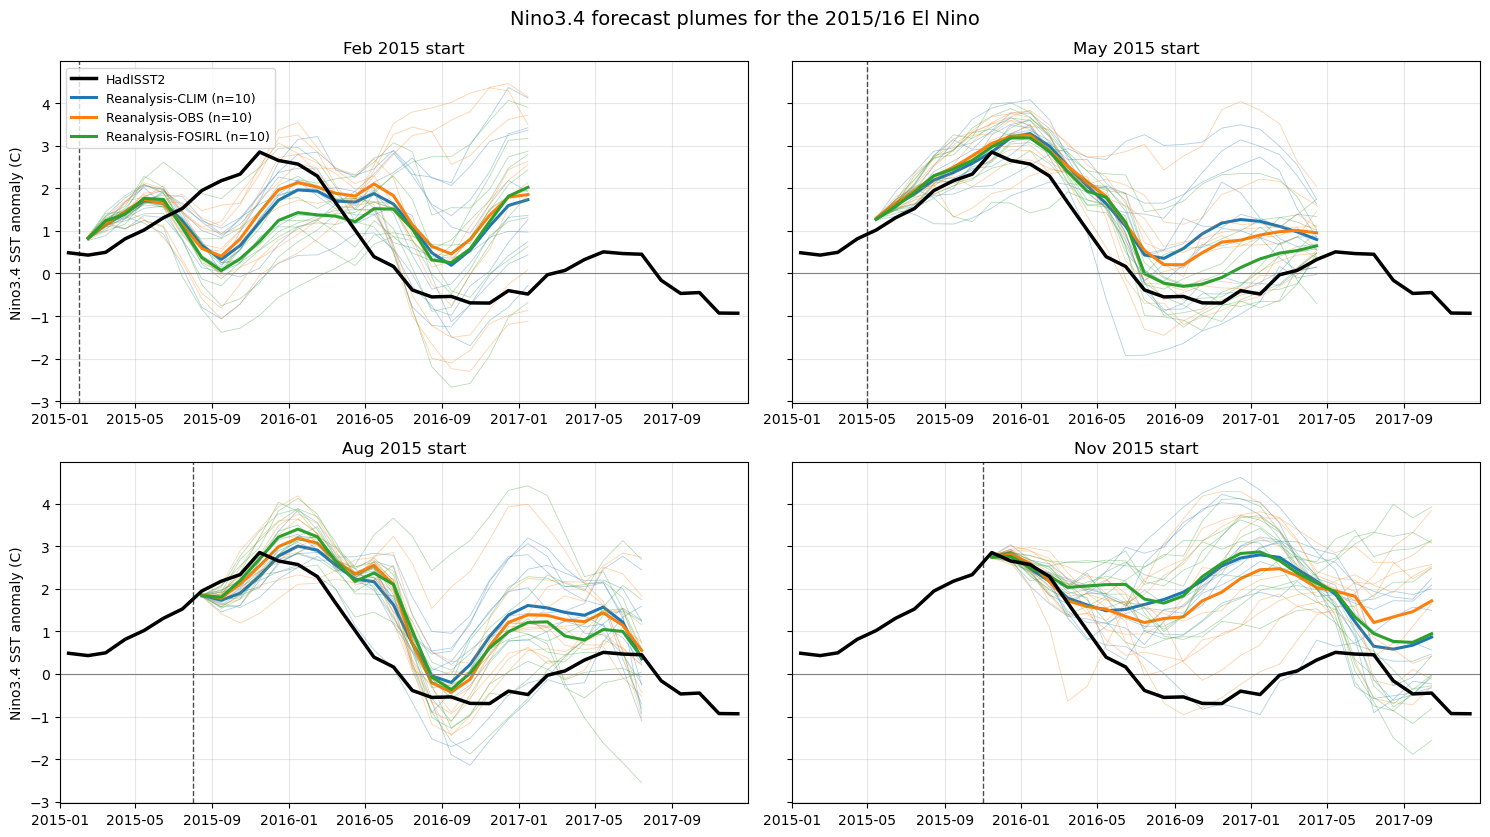

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_rtenso2026_case/fig_rtenso2026_enso_plume_oni.png


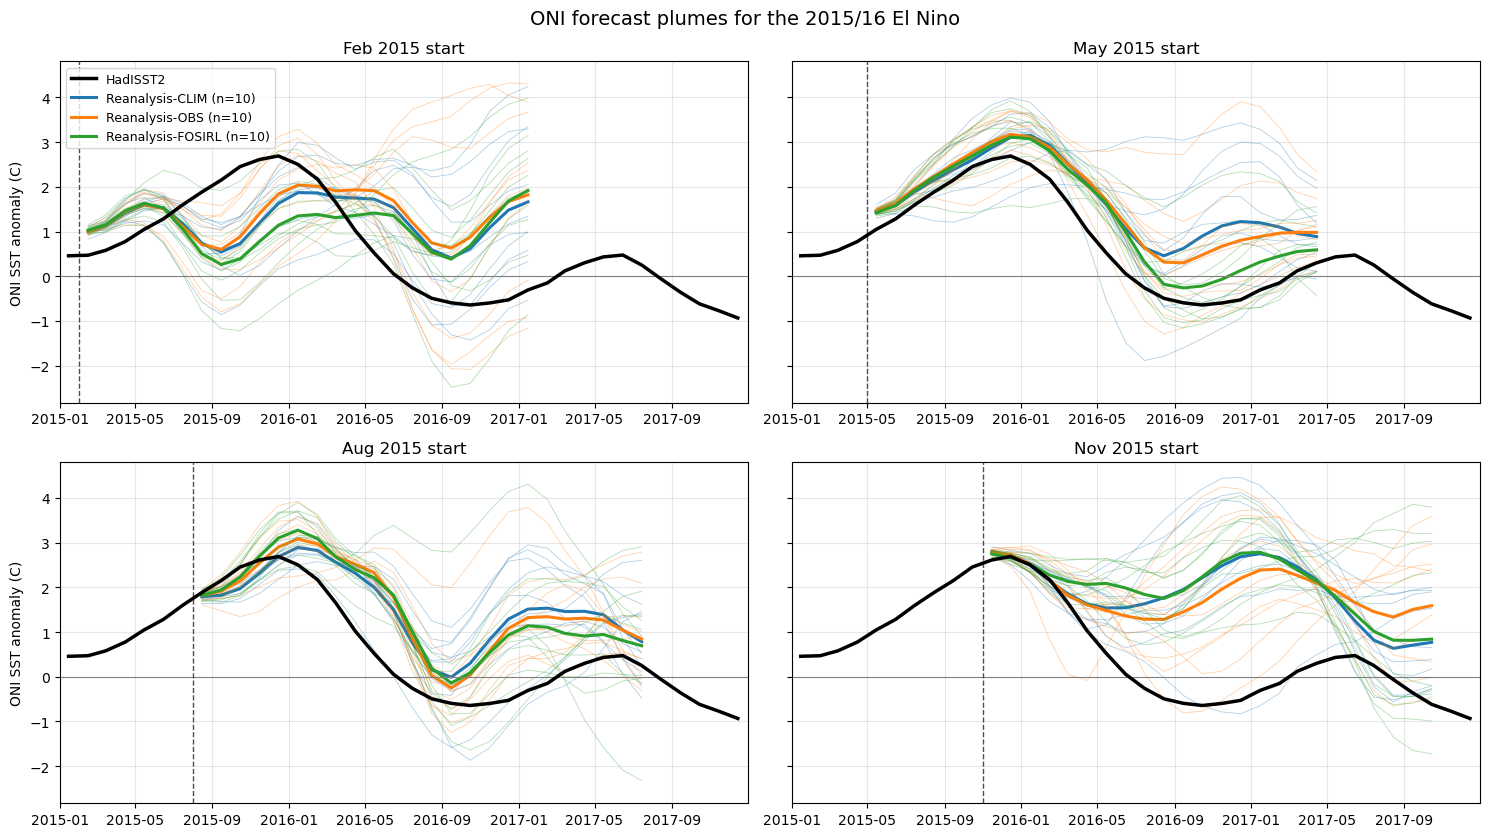

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_rtenso2026_case/fig_rtenso2026_enso_plume_nino3.png


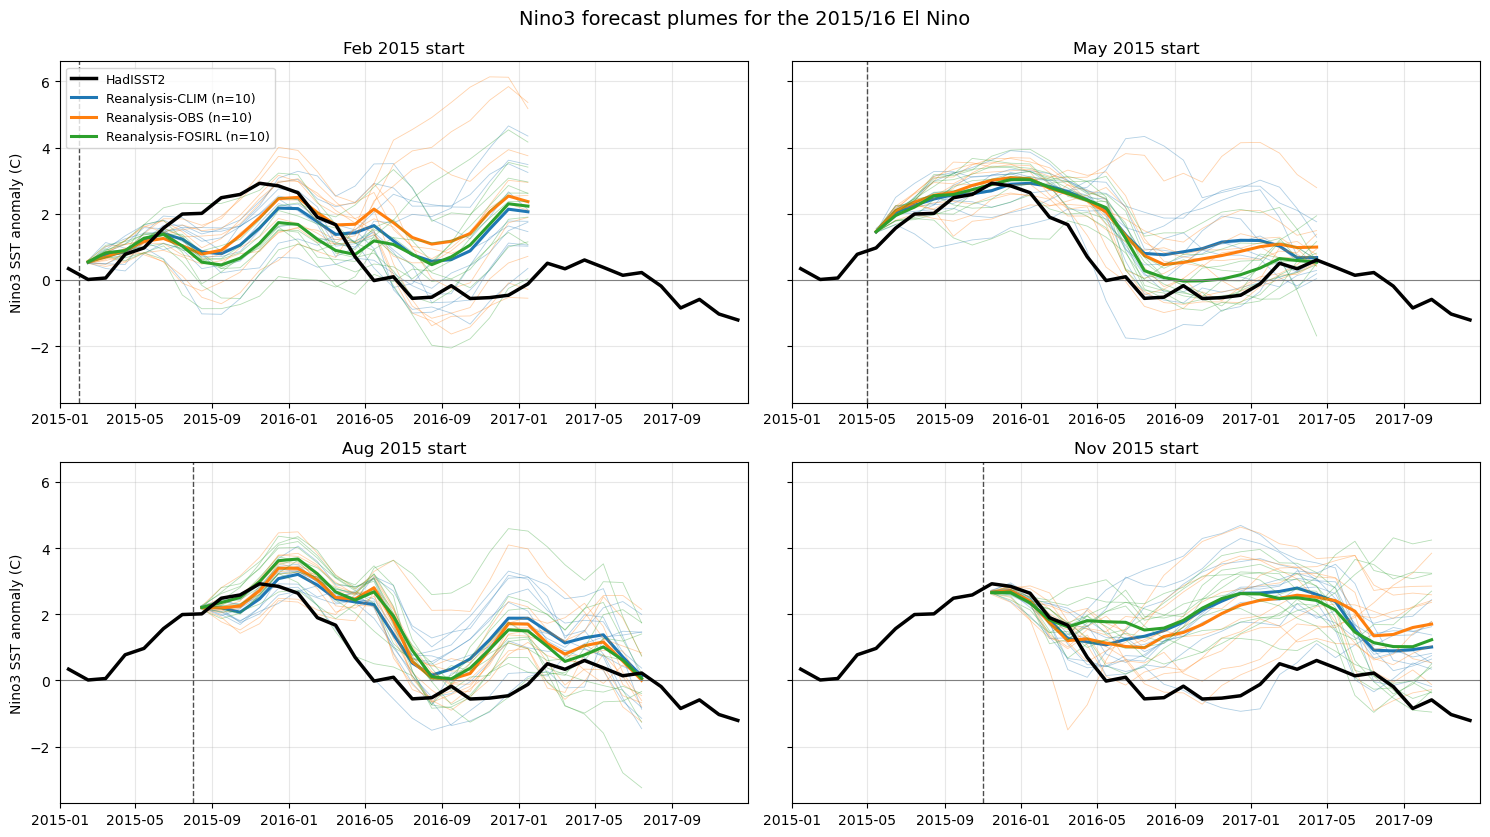

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_rtenso2026_case/fig_rtenso2026_enso_plume_nino4.png


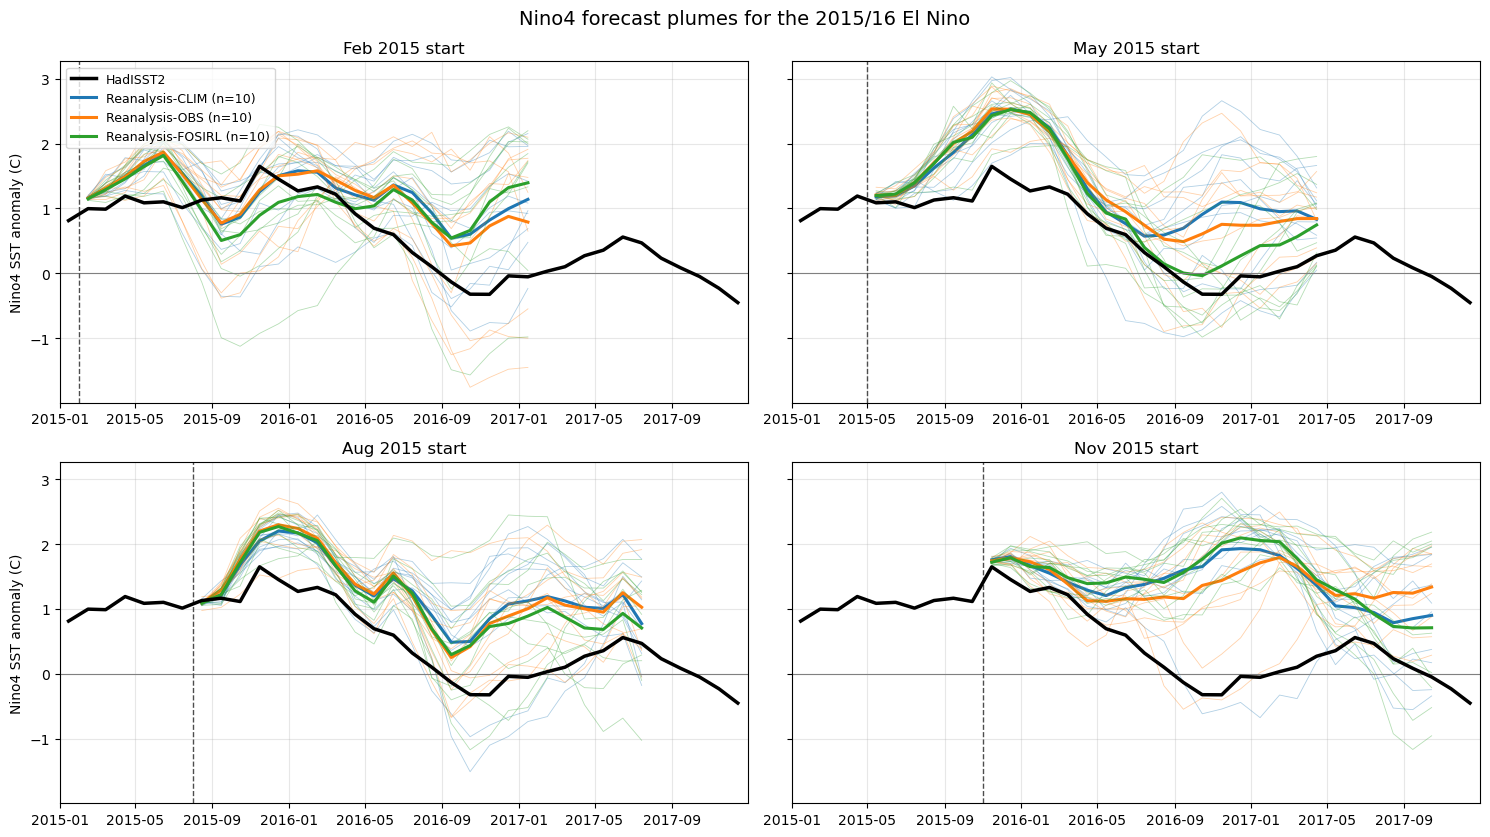

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_rtenso2026_case/fig_rtenso2026_enso_plume_nino12.png


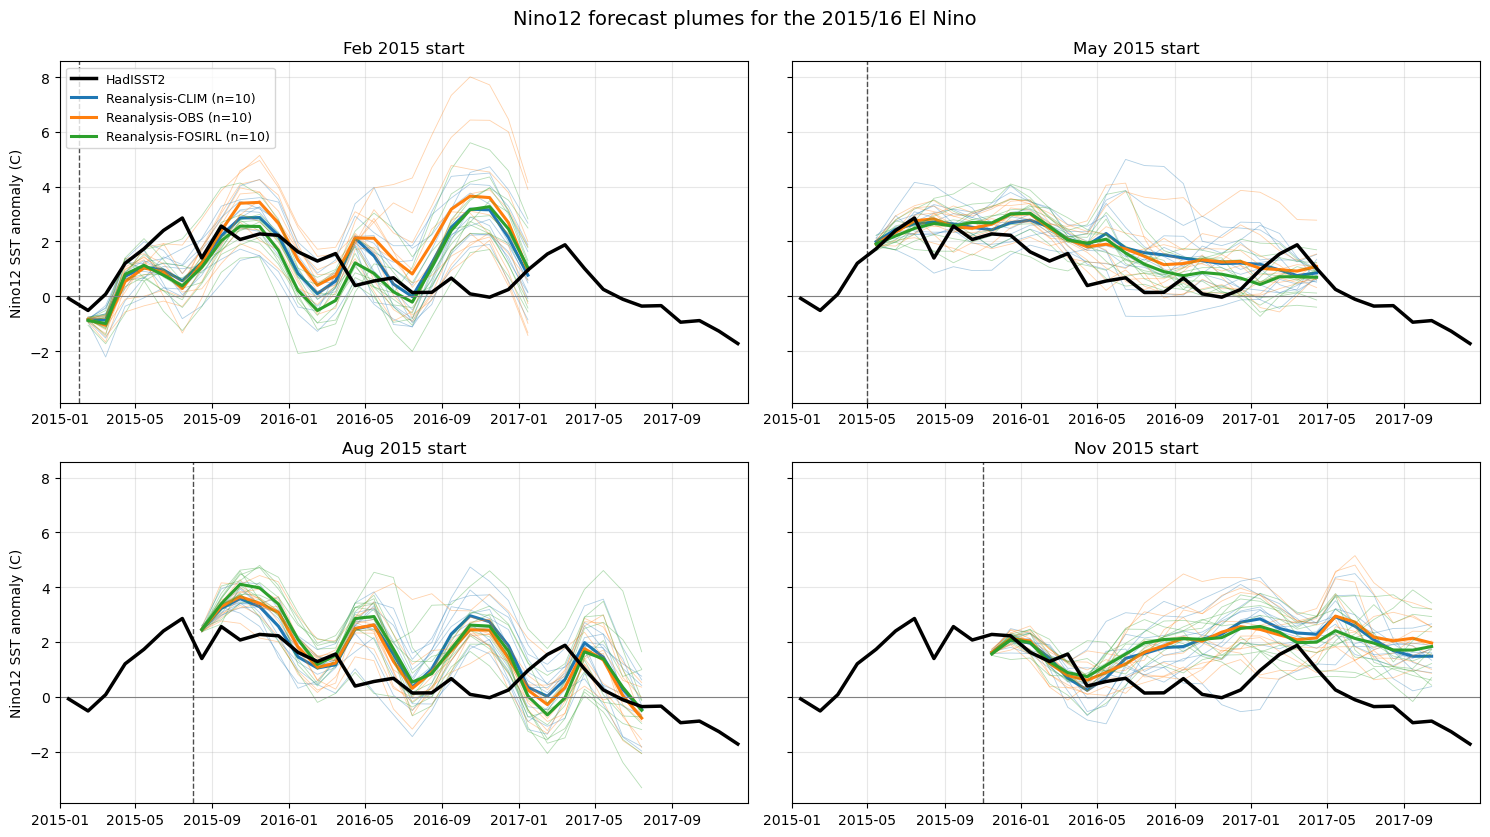

In [4]:
def plot_plume(index):
    fig, axes = plt.subplots(2, 2, figsize=(15, 8.5), sharey=True)
    obs = obs_index[index]
    for ax, init in zip(axes.flat, INIT_MONTHS):
        ax.plot(to_datetime(obs["time"].values), obs, color="k", lw=2.5, label="HadISST2", zorder=6)
        for case in CASES:
            ds = fc_index.get((case, init))
            if ds is None:
                continue
            color, x = CASES[case]["color"], to_datetime(ds["time"].values)
            for member in ds["member"].values:
                ax.plot(x, ds[index].sel(member=member), color=color, lw=0.6, alpha=0.35)
            ax.plot(x, ds[index].mean("member"), color=color, lw=2.2, label=f"{case} (n={ds.sizes['member']})")
        ax.axhline(0.0, color="0.5", lw=0.8)
        ax.axvline(datetime(CASE_YEAR, init, 1), color="0.3", ls="--", lw=1)
        ax.set_title(f"{MONTH_NAMES[init]} {CASE_YEAR} start", fontsize=12)
        ax.set_xlim(datetime(CASE_YEAR, 1, 1), datetime(CASE_YEAR + 2, 12, 31))
        ax.grid(alpha=0.3)
    for ax in axes[:, 0]:
        ax.set_ylabel(f"{index} SST anomaly (C)")
    axes[0, 0].legend(loc="upper left", fontsize=9)
    fig.suptitle(f"{index} forecast plumes for the 2015/16 El Nino", fontsize=14)
    fig.tight_layout()
    return fig


for index in INDICES:
    fig = plot_plume(index)
    print(rc.save_figure(fig, "rtenso2026", "enso_plume", index))
    plt.show()

### Peak-season summary

Ensemble-mean and member range of each index over the peak season, with the peak month of the ensemble mean.

In [5]:
rows = []
months = PEAK_SEASON["months"]
for index in INDICES:
    obs_peak_season = float(rc.obs_target_mean(obs_index[index], months))
    obs_2yr = obs_index[index].sel(time=slice(f"{CASE_YEAR}-01", f"{CASE_YEAR + 1}-12"))
    obs_peak = obs_2yr.isel(time=int(obs_2yr.argmax("time")))
    for (case, init), ds in fc_index.items():
        season = rc.target_mean(ds[index], months)
        if season is None:
            continue
        ens = ds[index].mean("member")
        peak = ens.isel(lead=int(ens.argmax("lead")))
        lead_to_season = [i for i, t in enumerate(ds["time"].values) if (t.year, t.month) == months[1]][0]
        rows.append({
            "index": index, "case": case, "start": MONTH_NAMES[init], "lead_to_centre_month": lead_to_season,
            "obs_peak_season": round(obs_peak_season, 2),
            "ens_mean_peak_season": round(float(season.mean("member")), 2),
            "member_min": round(float(season.min()), 2), "member_max": round(float(season.max()), 2),
            "error": round(float(season.mean("member")) - obs_peak_season, 2),
            "ens_peak": round(float(peak), 2), "ens_peak_month": f"{peak['time'].item().year}-{peak['time'].item().month:02d}",
            "obs_peak": round(float(obs_peak), 2), "obs_peak_month": f"{obs_peak['time'].item().year}-{obs_peak['time'].item().month:02d}",
        })
summary = pd.DataFrame(rows)
summary_file = OUTDIR / "RTENSO2026_case_Nino_peak_summary.csv"
summary.to_csv(summary_file, index=False)
print(summary_file)
summary[summary["index"] == "Nino3.4"]

/global/cfs/cdirs/e3sm/S2S2D/s2d_diag/RTENSO2026/case_study/sst_index/RTENSO2026_case_Nino_peak_summary.csv


,index,case,start,lead_to_centre_month,obs_peak_season,ens_mean_peak_season,member_min,member_max,error,ens_peak,ens_peak_month,obs_peak,obs_peak_month
0,Nino3.4,Reanalysis-CLIM,Feb,11,2.5,1.87,0.37,2.99,-0.63,1.96,2016-01,2.85,2015-11
1,Nino3.4,Reanalysis-CLIM,May,8,2.5,3.15,1.98,3.90,0.65,3.28,2016-01,2.85,2015-11
2,Nino3.4,Reanalysis-CLIM,Aug,5,2.5,2.89,2.41,3.58,0.39,3.00,2016-01,2.85,2015-11
3,Nino3.4,Reanalysis-CLIM,Nov,2,2.5,2.50,2.14,2.77,-0.01,2.84,2015-12,2.85,2015-11
4,Nino3.4,Reanalysis-OBS,Feb,11,2.5,2.04,0.51,3.29,-0.46,2.13,2016-01,2.85,2015-11
5,Nino3.4,Reanalysis-OBS,May,8,2.5,3.12,2.24,3.66,0.61,3.25,2016-01,2.85,2015-11
6,Nino3.4,Reanalysis-OBS,Aug,5,2.5,3.08,2.00,3.92,0.58,3.19,2016-01,2.85,2015-11
7,Nino3.4,Reanalysis-OBS,Nov,2,2.5,2.53,1.92,2.92,0.03,2.82,2015-12,2.85,2015-11
8,Nino3.4,Reanalysis-FOSIRL,Feb,11,2.5,1.35,-0.31,2.84,-1.15,2.02,2017-01,2.85,2015-11
9,Nino3.4,Reanalysis-FOSIRL,May,8,2.5,3.07,1.54,3.69,0.57,3.18,2016-01,2.85,2015-11


### Nino3.4 ensemble-mean error and spread by target month

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_rtenso2026_case/fig_rtenso2026_enso_plume_nino3_4_error_spread.png


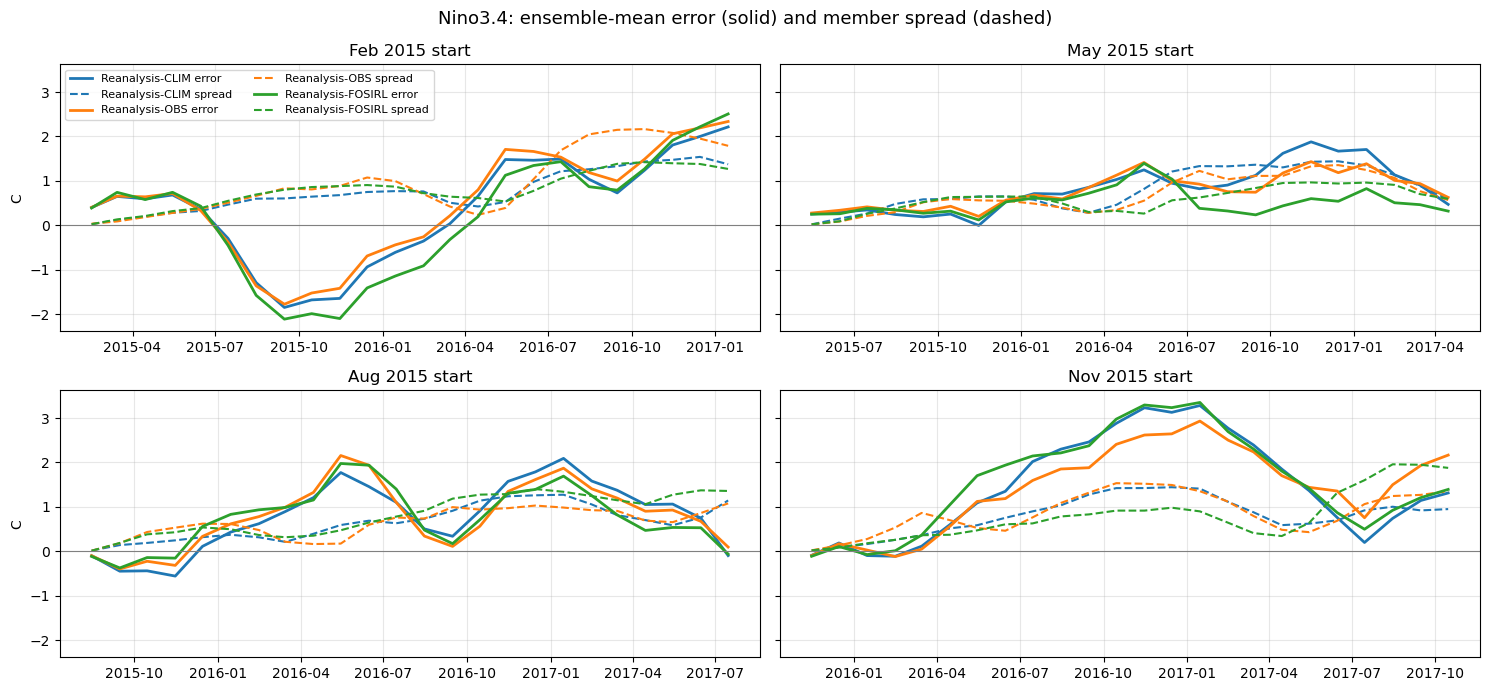

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(15, 7), sharey=True)
obs = obs_index["Nino3.4"]
for ax, init in zip(axes.flat, INIT_MONTHS):
    for case in CASES:
        ds = fc_index.get((case, init))
        if ds is None:
            continue
        fc = ds["Nino3.4"]
        error = fc.mean("member") - rc.match_obs(fc, obs)
        x, color = to_datetime(ds["time"].values), CASES[case]["color"]
        ax.plot(x, error, color=color, lw=2, label=f"{case} error")
        ax.plot(x, fc.std("member"), color=color, lw=1.5, ls="--", label=f"{case} spread")
    ax.axhline(0.0, color="0.5", lw=0.8)
    ax.set_title(f"{MONTH_NAMES[init]} {CASE_YEAR} start", fontsize=12)
    ax.grid(alpha=0.3)
for ax in axes[:, 0]:
    ax.set_ylabel("C")
axes[0, 0].legend(fontsize=8, ncol=2)
fig.suptitle("Nino3.4: ensemble-mean error (solid) and member spread (dashed)", fontsize=13)
fig.tight_layout()
print(rc.save_figure(fig, "rtenso2026", "enso_plume", "Nino3.4", "error_spread"))
plt.show()